In [1]:
%%capture
!pip3 install langchain langchain_core langchain_classic langchain_openai langchain_google_genai langchain_anthropic langchain_huggingface

# Notebook 2: Self-Correcting Code Agent

**Cursor Features We're Building:** Bugbot (detect and fix bugs automatically), Inline Edit (modify existing code), Rules (custom instructions that shape behavior)

In Notebook 1 we built an agent that generates code and writes files. But it has no idea if the code actually works. In this notebook we add the ability to **execute code, detect errors, and fix them automatically** — the same loop that powers Cursor's Bugbot.

### What's New

| Concept | Why |
|---|---|
| `with_structured_output` | Force the LLM to return Pydantic-validated structured responses |
| Conditional retry loop | Route back to generator on error, with a bounded retry count |
| Reflection node | A separate LLM call that reviews code quality after execution succeeds |
| Dynamic rules injection | Inject custom coding rules into the system prompt at runtime |

In [2]:
import os
from dotenv import load_dotenv
from google.colab import userdata

load_dotenv()

# api_key = os.getenv("OPENROUTER_API_KEY")
api_key = userdata.get("OPENROUTER_API_KEY")
print("API Key loaded" if api_key else "API Key NOT found")

API Key loaded


In [3]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="openai/gpt-4o-mini",
    openai_api_key=api_key,
    openai_api_base="https://openrouter.ai/api/v1",
)

response = llm.invoke("Say 'ready' if you can hear me.")
print(response.content)

Ready!


## Structured Output with `with_structured_output`

In NB1 the LLM returned free-text. For a code agent we need **structured responses** — the code separated from the explanation. `with_structured_output` binds a Pydantic model to the LLM so every response is validated.

In [5]:
from pydantic import BaseModel, Field


class CodeOutput(BaseModel):
    code: str = Field(description="The complete Python code to execute")
    explanation: str = Field(description="Brief explanation of what the code does")


structured_llm = llm.with_structured_output(CodeOutput)

result = structured_llm.invoke(
    # "What is the capital of France"
    "Write a Python function that checks if a number is prime"
)
print(f"Type: {type(result)}")
print(f"Explanation: {result.explanation}")
print(f"Code:\n{result.code}")

Type: <class '__main__.CodeOutput'>
Explanation: The function `is_prime(n)` checks if the input number `n` is a prime number. It returns `True` if `n` is prime and `False` otherwise. The function first eliminates numbers less than or equal to 1 as they are not prime. Then, it checks divisibility from 2 up to the square root of `n`, which is efficient for checking primality.
Code:
def is_prime(n):
    """
    Check if the provided number n is a prime number.
    A prime number is greater than 1 and is divisible only by 1 and itself.
    """
    if n <= 1:
        return False  # Numbers less than or equal to 1 are not prime
    for i in range(2, int(n**0.5) + 1):  # Check for factors up to the square root of n
        if n % i == 0:
            return False  # Found a factor, not prime
    return True  # No factors found, it is prime

# Example usage:
if __name__ == '__main__':
    number = 29
    if is_prime(number):
        print(f'{number} is a prime number.')
    else:
        print

The LLM now always returns a `CodeOutput` object — no parsing needed. This is how Cursor separates the code it generates from its explanation text.

## Code Execution

To self-correct, the agent needs to **run** the code. We create a simple executor that captures stdout and stderr.

In [6]:
import subprocess


def execute_python(code: str) -> dict:
    """Execute Python code in a subprocess and return stdout/stderr."""
    result = subprocess.run(
        ["python", "-c", code],
        capture_output=True,
        text=True,
        timeout=10,
    )
    return {
        "stdout": result.stdout,
        "stderr": result.stderr,
        "returncode": result.returncode,
    }


# Test with working code
out = execute_python("print('hello world')")
print("Working code:", out)

# Test with broken code
out = execute_python("print(1/0)")
print("Broken code:", out)

Working code: {'stdout': 'hello world\n', 'stderr': '', 'returncode': 0}
Broken code: {'stdout': '', 'stderr': 'Traceback (most recent call last):\n  File "<string>", line 1, in <module>\n    print(1/0)\n          ~^~\nZeroDivisionError: division by zero\n', 'returncode': 1}


## Building the Self-Correcting Graph

The core idea: **Generate → Execute → if error, loop back to Generate with the error message.**

This is the Prompt Chaining pattern (sequential steps) combined with the Reflection pattern (evaluate output, retry if needed). We cap retries at 3 to avoid infinite loops (Exception Handling pattern).

In [7]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END


class AgentState(TypedDict):
    task: str
    code: str
    explanation: str
    execution_result: str
    error: str
    attempts: int
    max_attempts: int
    status: str  # "generating", "executing", "success", "failed"


print("State defined")

State defined


In [8]:
from langchain_core.messages import SystemMessage, HumanMessage


def generate(state: AgentState) -> AgentState:
    """Generate code based on the task (and previous error if retrying)."""
    prompt = f"Write Python code for: {state['task']}"

    if state.get("error"):
        prompt += f"\n\nPrevious attempt failed with error:\n{state['error']}\n\nFix the code."

    result = structured_llm.invoke(prompt)

    return {
        "code": result.code,
        "explanation": result.explanation,
        "attempts": state.get("attempts", 0) + 1,
        "status": "executing",
        "error": "",
    }


def execute(state: AgentState) -> AgentState:
    """Execute the generated code and capture results."""
    result = execute_python(state["code"])

    if result["returncode"] == 0:
        return {
            "execution_result": result["stdout"],
            "error": "",
            "status": "success",
        }
    else:
        return {
            "execution_result": "",
            "error": result["stderr"],
            "status": "failed",
        }


def should_retry(state: AgentState) -> str:
    """Decide: success → end, error with retries left → regenerate, out of retries → end."""
    if state["status"] == "success":
        return "success"
    if state["attempts"] < state.get("max_attempts", 3):
        return "retry"
    return "give_up"


print("Nodes defined")

Nodes defined


In [9]:
graph = StateGraph(AgentState)

graph.add_node("generate", generate)
graph.add_node("execute", execute)

graph.add_edge(START, "generate")
graph.add_edge("generate", "execute")
graph.add_conditional_edges(
    "execute",
    should_retry,
    {
        "success": END,
        "retry": "generate",
        "give_up": END,
    },
)

bugbot = graph.compile()
print("Self-correcting graph compiled")

Self-correcting graph compiled


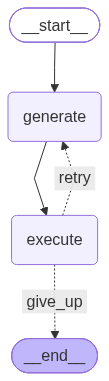

In [10]:
from IPython.display import Image, display

display(Image(bugbot.get_graph().draw_mermaid_png()))

Notice the loop: `execute` routes back to `generate` on failure. This is the conditional retry pattern — the same way Cursor's Bugbot detects an error and tries a fix.

## Test: Easy Task (should succeed first try)

In [11]:
result = bugbot.invoke(
    {
        "task": "Print the first 10 Fibonacci numbers",
        "attempts": 0,
        "max_attempts": 3,
    }
)

print(f"Status: {result['status']}")
print(f"Attempts: {result['attempts']}")
print(f"Explanation: {result['explanation']}")
print(f"Output: {result['execution_result']}")
print(f"Code:\n{result['code']}")

Status: success
Attempts: 1
Explanation: This code defines a function `fibonacci(n)` that generates the first `n` Fibonacci numbers. It initializes the first two Fibonacci numbers and then iteratively calculates the next ones. Finally, it prints the first 10 Fibonacci numbers.
Output: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34]

Code:
def fibonacci(n):
    fib_sequence = []
    a, b = 0, 1
    for _ in range(n):
        fib_sequence.append(a)
        a, b = b, a + b
    return fib_sequence

# Print the first 10 Fibonacci numbers
first_10_fib = fibonacci(10)
print(first_10_fib)


## Test: Harder Task (may need retries)

Let's give it something more complex where the first attempt might fail.

In [12]:
result = bugbot.invoke(
    {
        "task": """Create a function that:
1. Reads JSON from stdin
2. Flattens nested dictionaries (e.g. {"a": {"b": 1}} -> {"a.b": 1})
3. Prints the flattened result

Test it with this input: {"user": {"name": "Alice", "address": {"city": "NYC", "zip": "10001"}}, "active": true}
Use json.loads on a hardcoded string to simulate stdin.""",
        "attempts": 0,
        "max_attempts": 3,
    }
)

print(f"Status: {result['status']} (after {result['attempts']} attempt(s))")
if result["error"]:
    print(f"Final error: {result['error'][:200]}")
print(f"Output: {result['execution_result']}")

Status: success (after 1 attempt(s))
Output: {
  "user.name": "Alice",
  "user.address.city": "NYC",
  "user.address.zip": "10001",
  "active": true
}



### Tracing the Evolution of Code Across Every Attempt

To see exactly how the code changes and improves on every attempt, we can stream the execution of `bugbot` and print the complete code block generated at each `generate` step.

In [13]:
inputs = {
    "task": """Write a Python program to read the CSV file '/tmp/non_existent_file.csv' and print its contents.

CRITICAL RULE FOR ATTEMPT 1: Do NOT use any 'try/except' blocks, and do NOT use 'os.path.exists' or 'pathlib'. Write only the direct line to read the CSV using pandas.

If (and only if) you are retrying because of a previous FileNotFoundError, you may write code that creates the CSV file with dummy headers 'a,b' and rows '1,2' at '/tmp/non_existent_file.csv' before reading it.""",
    "attempts": 0,
    "max_attempts": 3,
}

print("=== Starting Self-Correction Trace ===\n")
for step in bugbot.stream(inputs):
    node_name = list(step.keys())[0]
    state = step[node_name]

    if node_name == "generate":
        print(f"--- [Node: generate] Attempt {state.get('attempts', '?')} Code Generated ---")
        print(state["code"])
        print("-" * 50 + "\n")
    elif node_name == "execute":
        if state.get("error"):
            print(f"--- [Node: execute] Execution Failed ---")
            print(f"Error: {state['error'].strip()}")
        else:
            print(f"--- [Node: execute] Execution Succeeded ---")
            print(f"Output:\n{state['execution_result'].strip()}")
        print("=" * 50 + "\n")

=== Starting Self-Correction Trace ===

--- [Node: generate] Attempt 1 Code Generated ---
import pandas as pd

# Attempting to read the CSV file directly
data = pd.read_csv('/tmp/non_existent_file.csv')
print(data)
--------------------------------------------------

--- [Node: execute] Execution Failed ---
Error: Traceback (most recent call last):
  File "<string>", line 4, in <module>
    data = pd.read_csv('/tmp/non_existent_file.csv')
  File "/usr/local/lib/python3.13/dist-packages/pandas/io/parsers/readers.py", line 1026, in read_csv
    return _read(filepath_or_buffer, kwds)
  File "/usr/local/lib/python3.13/dist-packages/pandas/io/parsers/readers.py", line 620, in _read
    parser = TextFileReader(filepath_or_buffer, **kwds)
  File "/usr/local/lib/python3.13/dist-packages/pandas/io/parsers/readers.py", line 1620, in __init__
    self._engine = self._make_engine(f, self.engine)
                   ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/pan

In [27]:
import os

# Reset the environment by deleting the generated file
file_path = '/tmp/non_existent_file.csv'
if os.path.exists(file_path):
    os.remove(file_path)
    print(f"Successfully deleted {file_path}. The environment is now reset!")
else:
    print(f"{file_path} does not exist. Ready for the test!")

/tmp/non_existent_file.csv does not exist. Ready for the test!


## Watching the Retry Loop

Let's trace the graph step-by-step to see when it retries.

In [14]:
inputs = {
    "task": "Use the 'statistics' module to compute mean, median, and stdev of [2, 4, 4, 4, 5, 5, 7, 9]. Print each on a separate line formatted as 'metric: value'.",
    "attempts": 0,
    "max_attempts": 3,
}

for step in bugbot.stream(inputs):
    node_name = list(step.keys())[0]
    state = step[node_name]

    if node_name == "generate":
        print(f"[generate] Attempt {state.get('attempts', '?')}")
        print(f"  Code preview: {state['code'][:80]}...")
    elif node_name == "execute":
        if state.get("error"):
            print(f"[execute] FAILED: {state['error'][:100]}")
        else:
            print(f"[execute] SUCCESS: {state['execution_result'][:100]}")
    print()

[generate] Attempt 1
  Code preview: import statistics

# Data list
data = [2, 4, 4, 4, 5, 5, 7, 9]

# Calculating me...

[execute] SUCCESS: mean: 5
median: 4.5
stdev: 2.138089935299395




## Adding a Reviewer — The Reflection Pattern

Passing execution isn't enough. Code can run but still be bad (no type hints, poor naming, inefficient). We add a **Reviewer node** that evaluates code quality after successful execution.

This is the Reflection pattern — a separate LLM call that evaluates the output against quality criteria and can send it back for revision.

In [15]:
class ReviewResult(BaseModel):
    approved: bool = Field(description="Whether the code meets quality standards")
    feedback: str = Field(
        description="Specific feedback for improvement if not approved"
    )


reviewer_llm = llm.with_structured_output(ReviewResult)

# Test the reviewer on some code
test_code = "x = [1,2,3]\nfor i in x:\n  print(i)"
review = reviewer_llm.invoke(
    f"Review this Python code for quality (type hints, naming, PEP 8, efficiency):\n\n{test_code}"
)
print(f"Approved: {review.approved}")
print(f"Feedback: {review.feedback}")

Approved: False
Feedback: The code is functional but lacks several aspects of quality coding practices. Here are the points for improvement:

1. **Type Hints**: Adding type hints helps improve code readability and maintainability. The variable `x` could be annotated to indicate its type.

2. **Naming**: The variable name 'x' is not descriptive. A more meaningful name should be used to indicate what the list represents.

3. **PEP 8 Compliance**: Keep a space after commas in the list. The standard would be to have the list defined as `x = [1, 2, 3]`. Additionally, use the proper indentation (4 spaces) for any blocks of code (though in this case, it's simple enough).

4. **Efficiency**: For very small lists, efficiency is not a big concern, but if you plan on using this in a larger context, consider ways to optimize or standardize printing methods such as joining vs. printing in a loop.

Revised Code:
```python
from typing import List

def print_numbers(numbers: List[int]) -> None:
    fo

## Full Graph: Generate → Execute → Review

Now we wire it all together: generate code, execute it, if it passes execution send to reviewer, if reviewer rejects send back to generator with feedback.

In [16]:
class FullAgentState(TypedDict):
    task: str
    rules: str  # custom coding rules
    code: str
    explanation: str
    execution_result: str
    error: str
    review_feedback: str
    attempts: int
    max_attempts: int
    status: str


def generate_v2(state: FullAgentState) -> FullAgentState:
    prompt = f"Write Python code for: {state['task']}"

    if state.get("rules"):
        prompt = f"Follow these rules:\n{state['rules']}\n\n{prompt}"

    if state.get("error"):
        prompt += f"\n\nPrevious attempt had an execution error:\n{state['error']}\n\nFix the code."
    elif state.get("review_feedback"):
        prompt += f"\n\nPrevious code worked but the reviewer said:\n{state['review_feedback']}\n\nImprove the code."

    result = structured_llm.invoke(prompt)
    return {
        "code": result.code,
        "explanation": result.explanation,
        "attempts": state.get("attempts", 0) + 1,
        "status": "executing",
        "error": "",
        "review_feedback": "",
    }


def execute_v2(state: FullAgentState) -> FullAgentState:
    result = execute_python(state["code"])
    if result["returncode"] == 0:
        return {"execution_result": result["stdout"], "error": "", "status": "executed"}
    else:
        return {
            "execution_result": "",
            "error": result["stderr"],
            "status": "exec_failed",
        }


def review(state: FullAgentState) -> FullAgentState:
    result = reviewer_llm.invoke(
        f"Review this Python code for quality (type hints, naming, PEP 8, efficiency, correctness):\n\n{state['code']}"
    )
    if result.approved:
        return {"status": "approved", "review_feedback": ""}
    else:
        return {"status": "review_failed", "review_feedback": result.feedback}


def route_after_execute(state: FullAgentState) -> str:
    if state["status"] == "executed":
        return "review"
    if state["attempts"] < state.get("max_attempts", 3):
        return "retry"
    return "give_up"


def route_after_review(state: FullAgentState) -> str:
    if state["status"] == "approved":
        return "done"
    if state["attempts"] < state.get("max_attempts", 3):
        return "revise"
    return "done"


print("Full agent nodes defined")

Full agent nodes defined


In [17]:
graph = StateGraph(FullAgentState)

graph.add_node("generate", generate_v2)
graph.add_node("execute", execute_v2)
graph.add_node("review", review)

graph.add_edge(START, "generate")
graph.add_edge("generate", "execute")
graph.add_conditional_edges(
    "execute",
    route_after_execute,
    {
        "review": "review",
        "retry": "generate",
        "give_up": END,
    },
)
graph.add_conditional_edges(
    "review",
    route_after_review,
    {
        "done": END,
        "revise": "generate",
    },
)

full_agent = graph.compile()
print("Full agent compiled")

Full agent compiled


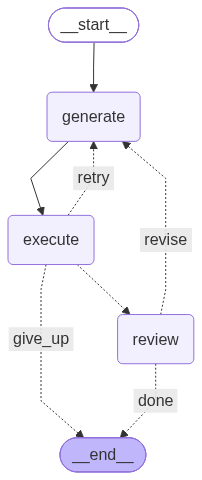

In [33]:
display(Image(full_agent.get_graph().draw_mermaid_png()))

Two loops visible: execute can loop back on error, and review can loop back for quality improvements. Both bounded by `max_attempts`.

## Running the Full Agent

In [18]:
result = full_agent.invoke(
    {
        "task": "Write a function to find all prime numbers up to n using the Sieve of Eratosthenes. Test it by printing primes up to 50.",
        "rules": "",
        "attempts": 0,
        "max_attempts": 3,
    }
)

print(f"Status: {result['status']} (after {result['attempts']} attempt(s))")
print(f"Output: {result['execution_result']}")
print(f"\nCode:\n{result['code']}")

Status: approved (after 2 attempt(s))
Output: [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47]


Code:
def sieve_of_eratosthenes(n: int) -> list[int]:
    """
    Uses the Sieve of Eratosthenes algorithm to find all prime numbers up to n.

    :param n: The upper limit to find prime numbers.
    :return: A list of prime numbers up to n.
    """
    if n < 2:
        return []  # No primes less than 2

    is_prime = [True] * (n + 1)  # True means "assumed prime"
    is_prime[0] = is_prime[1] = False  # 0 and 1 are not primes

    for i in range(2, int(n**0.5) + 1):  # Check for factors up to sqrt(n)
        if is_prime[i]:  # If i is still considered prime
            for multiple in range(i * i, n + 1, i):  # Mark multiples of i as non-prime
                is_prime[multiple] = False

    return [num for num, prime in enumerate(is_prime) if prime]  # Return list of primes

# Test the function by printing primes up to 50
primes_up_to_50 = sieve_of_eratosthenes(50)
print(primes_

## Tracing the Full Pipeline

Let's stream each step to see Generate -> Execute -> Review in action.

In [19]:
for step in full_agent.stream(
    {
        "task": "Create a dataclass called 'Point' with x,y coordinates. Add methods for distance_to(other), midpoint(other), and __str__. Test with Point(3,4) and Point(0,0).",
        "rules": "",
        "attempts": 0,
        "max_attempts": 3,
    }
):
    node_name = list(step.keys())[0]
    state = step[node_name]

    if node_name == "generate":
        print(
            f"[generate] Attempt {state.get('attempts', '?')}: {state.get('explanation', '')[:100]}"
        )
    elif node_name == "execute":
        if state.get("error"):
            print(f"[execute] FAILED: {state['error'][:150]}")
        else:
            print(f"[execute] OK: {state['execution_result'][:150]}")
    elif node_name == "review":
        status = state.get("status", "")
        feedback = state.get("review_feedback", "")
        print(f"[review] {status}: {feedback[:150]}")
    print()

[generate] Attempt 1: This code defines a dataclass called 'Point' that represents a point in 2D space with x and y coordi

[execute] OK: Distance from Point(3, 4) to Point(0, 0): 5.0
Midpoint between Point(3, 4) and Point(0, 0): Point(1.5, 2.0)


[review] approved: 



## Custom Rules — Like Cursor Rules

Cursor lets you define rules in `.cursorrules` files that shape how the AI writes code. We do the same by injecting custom rules into the generator's prompt at runtime. This is dynamic state injection — the rules are part of the graph state, not hardcoded.

In [20]:
# Without rules
result_no_rules = full_agent.invoke(
    {
        "task": "Write a function to sort a list of dictionaries by a given key. Test with sample data.",
        "rules": "",
        "attempts": 0,
        "max_attempts": 3,
    }
)

print("=== Without Rules ===")
print(result_no_rules["code"])

=== Without Rules ===
def sort_list_of_dicts_by_key(data, sort_key, default=None):
    return sorted(
        data,
        key=lambda x: x.get(sort_key, default)
    )

# Sample data to test the function
sample_data = [
    {'name': 'Alice', 'age': 30},
    {'name': 'Bob', 'age': 25},
    {'name': 'Charlie', 'age': None},
    {'name': 'David', 'age': 35}
]

# Testing the function
sorted_data = sort_list_of_dicts_by_key(sample_data, 'age')
print(sorted_data)


In [21]:
# With strict rules
STRICT_RULES = """- ALL functions must have type hints on parameters and return type
- ALL functions must have a Google-style docstring
- Use list comprehensions instead of loops where possible
- Add if __name__ == '__main__' guard for test code
- Variable names must be descriptive (no single letters except loop counters)"""

result_with_rules = full_agent.invoke(
    {
        "task": "Write a function to sort a list of dictionaries by a given key. Test with sample data.",
        "rules": STRICT_RULES,
        "attempts": 0,
        "max_attempts": 3,
    }
)

print("=== With Rules ===")
print(result_with_rules["code"])

=== With Rules ===
from typing import List, Dict, Any


def sort_dict_list(dict_list: List[Dict[str, Any]], sort_key: str) -> List[Dict[str, Any]]:
    """
    Sorts a list of dictionaries by a specified key.

    Args:
        dict_list (List[Dict[str, Any]]): The list of dictionaries to sort.
        sort_key (str): The key to sort the dictionaries by.

    Returns:
        List[Dict[str, Any]]: A new list of dictionaries sorted by the specified key.
    """
    return sorted(dict_list, key=lambda dictionary: dictionary.get(sort_key))


if __name__ == '__main__':
    # Sample data for testing
    sample_data: List[Dict[str, Any]] = [
        {'name': 'Alice', 'age': 30},
        {'name': 'Bob', 'age': 25},
        {'name': 'Charlie', 'age': 35}
    ]
    # Sort by age
    sorted_data: List[Dict[str, Any]] = sort_dict_list(sample_data, 'age')
    print(sorted_data)  # Expected output: [{'name': 'Bob', 'age': 25}, {'name': 'Alice', 'age': 30}, {'name': 'Charlie', 'age': 35}]


## Inline Edit — Modify Existing Code

Cursor's Inline Edit (Cmd+K) takes existing code and modifies it based on instructions. We build this by passing existing code + edit instructions to the generator.

In [39]:
existing_code = """
def greet(name):
    print("Hello " + name)

greet("World")
"""

user_prompt_from_ui = """
Changes requested:
- Add type hints
- Add a docstring
- Support an optional greeting parameter (default "Hello")
- Return the string instead of printing it
- Add tests that verify the output
"""

result = full_agent.invoke(
    {
        "task": f"""Modify this existing code:
```python
{existing_code}
```
{user_prompt_from_ui}
        """,
        "rules": "",
        "attempts": 0,
        "max_attempts": 3,
    }
)

print(f"Status: {result['status']} (attempts: {result['attempts']})")
print(f"Output: {result['execution_result']}")
print(f"\nModified code:\n{result['code']}")

Status: approved (attempts: 1)
Output: Hello World
All tests passed.


Modified code:
def greet(name: str, greeting: str = "Hello") -> str:
    """
    Generate a greeting message.

    Parameters:
    name (str): The name of the person to greet.
    greeting (str): The greeting phrase (default is 'Hello').

    Returns:
    str: The complete greeting message.
    """
    return f"{greeting} {name}"

# Example of using the function
if __name__ == "__main__":
    print(greet("World"))  # Should print 'Hello World'

# Tests

def test_greet():
    assert greet("Alice") == "Hello Alice"
    assert greet("Bob", "Good morning") == "Good morning Bob"
    assert greet("Charlie", "Hi") == "Hi Charlie"
    assert greet("Dana", "Greetings") == "Greetings Dana"
    assert greet("Eve", "") == " Eve"

# Run the tests
if __name__ == "__main__":
    test_greet()
    print("All tests passed.")


## Combining Rules + Inline Edit

This is where it gets powerful — edit existing code while enforcing custom rules.

In [22]:
legacy_code = """
import csv

def read_data(file):
    f = open(file)
    r = csv.reader(f)
    data = []
    for row in r:
        data.append(row)
    f.close()
    return data

d = read_data("test.csv")
print(d)
"""

MODERNIZE_RULES = """- Use context managers (with statement) for file handling
- Use pathlib.Path instead of string paths
- Use list comprehensions where appropriate
- Add proper error messages
- Use type hints everywhere"""

result = full_agent.invoke(
    {
        "task": f"""Modernize this legacy code:
```python
{legacy_code}
```
Rewrite it following modern Python best practices. Create a small test CSV inline using io.StringIO for testing.""",
        "rules": MODERNIZE_RULES,
        "attempts": 0,
        "max_attempts": 3,
    }
)

print(f"Status: {result['status']} (attempts: {result['attempts']})")
print(f"Output: {result['execution_result']}")
print(f"\nModernized code:\n{result['code']}")

Status: review_failed (attempts: 3)
Output: [['name', 'age', 'city'], ['Alice', '30', 'New York'], ['Bob', '25', 'Los Angeles'], ['Charlie', '35', 'Chicago']]


Modernized code:
import csv
import io
from pathlib import Path
from typing import List, Iterator


def read_data(file_path: Path) -> Iterator[List[str]]:
    """Reads CSV data from the given file path and returns an iterator of rows."""
    if not file_path.is_file():
        raise FileNotFoundError(f"The file '{file_path}' does not exist.")

    with file_path.open(mode='r', newline='') as f:
        reader = csv.reader(f)
        for row in reader:
            yield row


if __name__ == '__main__':
    # Creating a small test CSV using io.StringIO
    test_csv_data = io.StringIO("""name,age,city\nAlice,30,New York\nBob,25,Los Angeles\nCharlie,35,Chicago""")
    test_file_path = Path('test.csv')

    # Writing test data to a temporary file
    with test_file_path.open('w', newline='') as f:
        f.write(test_csv_data.getval

## Recap

| What we built | Cursor equivalent |
|---|---|
| `with_structured_output` for code/explanation | Cursor separating code from explanation in Chat |
| Generate -> Execute retry loop | Bugbot detecting and auto-fixing errors |
| Reviewer node with quality checks | Cursor's code review suggestions |
| Custom rules in state | Cursor Rules (`.cursorrules` files) |
| Inline edit (modify existing code) | Cmd+K inline edit |

### Design Patterns Used

- **Prompt Chaining** -- Generate -> Execute -> Review as sequential pipeline
- **Reflection** -- Reviewer evaluates output quality, can reject and retry
- **Exception Handling** -- Bounded retries, categorized failures (exec error vs review rejection)

### Next Notebook

The agent works on single tasks. In Notebook 3 we build the full production agent: multiple specialized agents, codebase search, human review before applying changes, parallel code generation, and shell command execution.